# The adaptive cut on every scipy linkage method

Any scipy linkage matrix works: `single`, `complete`, `average`, `weighted`, `ward`, `centroid`
and `median`. Centroid and median trees can have inversions (a merge lower than the one below
it); they have no single-level cut, so the sampler starts from all singletons there.

This notebook needs `pip install adaptive_cut scikit-learn matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import linkage
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score as ari

import adaptive_cut as ac

In [2]:
def blobs(seed=0):
    """Three tight blobs (150 points each) next to two wide ones (300 each)."""
    rng = np.random.default_rng(seed)
    centers = np.array([[0, 0], [1.2, 0], [0.6, 1.0], [8, 0], [4, 7]])
    std = np.array([0.25, 0.25, 0.25, 1.6, 1.6])
    y = np.repeat(np.arange(5), [150, 150, 150, 300, 300])
    X = centers[y] + std[y, None] * rng.standard_normal((len(y), 2))
    return X, y


X, y = blobs(seed=0)
X2, y2 = make_blobs(
    1000, cluster_std=[1.0, 2.5, 0.5], random_state=170
)  # scikit-learn's "varied" blobs
datasets = {"tight and wide blobs": (X, y), "varied blobs": (X2, y2)}

## Every linkage method, default sampler settings

Each tree is scored by the Gaussian BIC and cut twice: at the best single level, and by the
adaptive cut with its default settings (`T="auto"`).

In [3]:
METHODS = ["single", "complete", "average", "weighted", "ward", "centroid", "median"]

for dname, (Xd, yd) in datasets.items():
    print(dname)
    for method in METHODS:
        Z = linkage(Xd, method)
        scores = ac.gaussian_scores(Z, Xd)
        monotone = bool(np.all(np.diff(Z[:, 2]) >= 0))
        res = ac.adaptive_cut(
            Z, scores, T="auto", init="best_level" if monotone else "leaves", rng=0
        )
        if monotone:
            level = ac.best_level_cut(Z, scores)
            lv = f"{level.n_clusters:3d} clusters ARI {ari(yd, level.labels):.2f}"
        else:
            lv = "      no single-level cut"
        print(
            f"  {method:>9}: single-level {lv} | adaptive {res.n_clusters:3d} clusters ARI {ari(yd, res.labels):.2f}"
        )

tight and wide blobs


     single: single-level  17 clusters ARI 0.67 | adaptive  15 clusters ARI 0.67
   complete: single-level  11 clusters ARI 0.33 | adaptive   6 clusters ARI 0.47
    average: single-level   3 clusters ARI 0.70 | adaptive   3 clusters ARI 0.70
   weighted: single-level   6 clusters ARI 0.42 | adaptive   5 clusters ARI 0.48
       ward: single-level   3 clusters ARI 0.69 | adaptive   3 clusters ARI 0.69
   centroid: single-level       no single-level cut | adaptive   3 clusters ARI 0.69


     median: single-level       no single-level cut | adaptive   4 clusters ARI 0.48
varied blobs
     single: single-level  30 clusters ARI 0.89 | adaptive  28 clusters ARI 0.89
   complete: single-level   9 clusters ARI 0.73 | adaptive   8 clusters ARI 0.80
    average: single-level   9 clusters ARI 0.76 | adaptive   4 clusters ARI 0.90
   weighted: single-level   5 clusters ARI 0.77 | adaptive   5 clusters ARI 0.77
       ward: single-level   3 clusters ARI 0.95 | adaptive   3 clusters ARI 0.95
   centroid: single-level       no single-level cut | adaptive   3 clusters ARI 0.95
     median: single-level       no single-level cut | adaptive   5 clusters ARI 0.67


With its default temperature the sampler often keeps the single-level cut (for example Ward on
the tight and wide blobs). Notebook 01 shows how a higher `T` lets it reach the 5-cluster cut.

## Covariance model of the Gaussian score

`gaussian_scores(Z, X, covariance=...)` models each cluster with one variance per dimension
(`"diag"`, the default), one variance for all dimensions (`"spherical"`) or a full covariance
matrix (`"full"`). Stretched clusters need `"full"`.

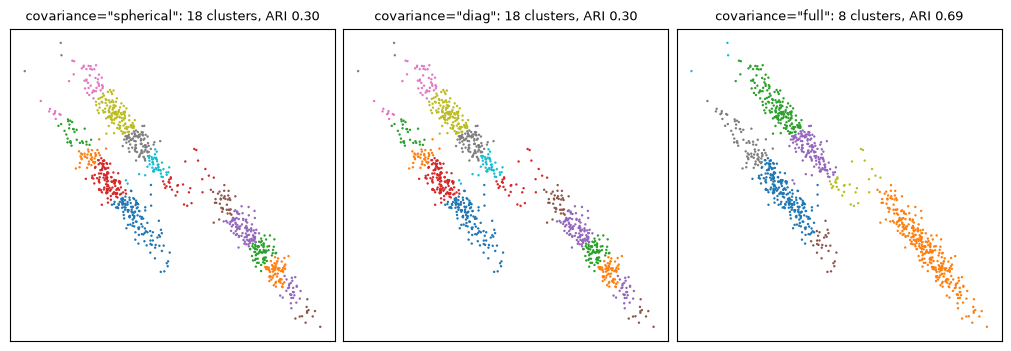

In [4]:
X3, y3 = make_blobs(1000, random_state=170)
X3 = X3 @ np.array([[0.6, -0.6], [-0.4, 0.8]])  # scikit-learn's anisotropic blobs
Z = linkage(X3, "average")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), layout="constrained")
for ax, cov in zip(axes, ["spherical", "diag", "full"]):
    res = ac.adaptive_cut(Z, ac.gaussian_scores(Z, X3, covariance=cov), T="auto", rng=0)
    ax.scatter(X3[:, 0], X3[:, 1], s=3, c=res.labels % 10, cmap="tab10", linewidths=0)
    ax.set_title(
        f'covariance="{cov}": {res.n_clusters} clusters, ARI {ari(y3, res.labels):.2f}', fontsize=9
    )
    ax.set_xticks([])
    ax.set_yticks([])

## Your own objective

Any per-cluster score works, as long as the objective of a partition is the sum of the scores
of its clusters. `node_scores(Z, func)` calls `func(leaf_ids)` on every node of the tree. Here
the Gaussian BIC is written by hand as a function of one cluster; it gives the same scores as
`ac.gaussian_scores`, which computes them faster on large trees. To minimise a cost, negate it.

In [5]:
Z = linkage(X, "ward")
N, d = X.shape
floor = 0.01 * X.var(axis=0)


def gaussian_bic(idx):  # score of the cluster made of the points X[idx]
    P = X[idx]
    m = len(P)
    vhat = P.var(axis=0)
    v = np.maximum(vhat, floor)
    loglik = -0.5 * m * np.sum(np.log(2 * np.pi * v) + vhat / v)
    return loglik + m * np.log(m) - 0.5 * (2 * d + 1) * np.log(N)


scores = ac.node_scores(Z, gaussian_bic)
print("same as ac.gaussian_scores:", np.allclose(scores, ac.gaussian_scores(Z, X)))
res = ac.adaptive_cut(Z, scores, T=160, n_steps=100_000, rng=0)
print(res.best, f"ARI {ari(y, res.labels):.2f}")

same as ac.gaussian_scores: True
Cut(n_clusters=5, value=3225.84) ARI 0.96
